# Lab 4 — Candidate Moves in Steepest Local Search for Selective TSP with Node Costs

Authors: Wiktor Talarek 160225, Daniel Skalski 160261

This notebook implements the Lab 4 assignment: improve the time efficiency of the **steepest local search**
by evaluating only **candidate moves**. The neighbourhood that proved best in Lab 3 is reused:
**2-opt intra-route moves + inter-route node exchange**. The baseline is the full steepest local search
without candidate moves.

## 1. Helpers and parameters

- `n = 200`, `k = ceil(n / 2) = 100` nodes must be selected.
- Distances are Euclidean distances rounded to the nearest integer and are precomputed once.
- Objective: `sum dist[tour[i], tour[i+1]] + sum cost[tour[i]]`.
- Candidate list: for every vertex, the `K = 10` nearest vertices by `dist[i,j] + cost[j]`
  (self excluded). `K` is also tested experimentally.
- 200 random starting solutions per instance. The same 200 starts are reused by every method,
  so the comparison is paired.

In [1]:
%matplotlib inline
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

DATA = Path('data')
FIG = Path('figures')
SOL = Path('solutions')
INSTANCES = ['TSPA', 'TSPB']
RNG_SEED = 0
NUM_RUNS = 200
K_DEFAULT = 10
K_VALUES = [5, 10, 15, 20, 30]
INF = np.iinfo(np.int64).max // 4


def load_instance(name: str):
    d = np.loadtxt(DATA / f'{name}.csv', delimiter=';', dtype=int)
    xy, costs = d[:, :2], d[:, 2]
    diff = xy[:, None, :] - xy[None, :, :]
    dist = np.rint(np.sqrt((diff ** 2).sum(axis=-1))).astype(np.int64)
    n = len(costs)
    k = (n + 1) // 2
    return {'name': name, 'xy': xy, 'costs': costs, 'dist': dist, 'n': n, 'k': k}


def compute_cost(tour, dist, costs) -> int:
    t = np.asarray(tour, dtype=int)
    return int(dist[t, np.roll(t, -1)].sum() + costs[t].sum())


def check_solution(tour, n: int, k: int):
    t = list(tour)
    if len(t) != k:
        return False, f'length {len(t)} != k={k}'
    if len(set(t)) != k:
        return False, 'duplicate nodes'
    if any(v < 0 or v >= n for v in t):
        return False, 'index out of range'
    return True, 'ok'


def random_tour(n: int, k: int, rng: np.random.Generator) -> list[int]:
    selected = rng.choice(n, size=k, replace=False)
    rng.shuffle(selected)
    return [int(v) for v in selected]


def build_candidates(D, C, K: int):
    """For every vertex: K nearest vertices by D[i,j] + C[j] (self excluded)."""
    n = len(C)
    scores = D + C[None, :]
    scores[np.arange(n), np.arange(n)] = INF
    return np.argsort(scores, axis=1, kind='stable')[:, :K]


problems = {name: load_instance(name) for name in INSTANCES}
print('loaded instances:', {n: (problems[n]['n'], problems[n]['k']) for n in INSTANCES})

loaded instances: {'TSPA': (200, 100), 'TSPB': (200, 100)}


## 2. Baseline: full steepest local search (best Lab 3 neighbourhood)

At every iteration the whole neighbourhood is scanned: all inter-route exchanges (one selected node
replaced by one unselected node) and all 2-opt intra-route moves. The single best improving move is
applied. Every delta is computed in `O(1)` from the distance matrix and node costs.

```text
STEEPEST_FULL(tour, used, D, C, k, n):
    repeat:
        best_delta <- 0
        for each selected position p and each unselected node u:
            d <- D[prev(p),u] + D[u,next(p)] - D[prev(p),tour[p]] - D[tour[p],next(p)] + C[u] - C[tour[p]]
            update best_delta
        for each non-adjacent pair (i,j):
            d <- D[tour[i],tour[j]] + D[tour[i+1],tour[j+1]] - D[tour[i],tour[i+1]] - D[tour[j],tour[j+1]]
            update best_delta
        if best_delta >= 0: break
        apply best move; cost <- cost + best_delta
```

In [2]:
def steepest_ls_opt(tour, used, D, C, k, n):
    """Full steepest local search: inter-route exchange + 2-opt intra-route moves."""
    t = np.array(tour, dtype=int).copy()
    used = used.copy()
    cost = compute_cost(t, D, C)
    iters = 0
    while True:
        iters += 1
        pos = np.arange(k)
        prev = t[(pos - 1) % k]
        nxt = t[(pos + 1) % k]
        s = t[pos]
        U = np.flatnonzero(~used)
        m = len(U)
        best_delta = 0
        best_move = None
        if m > 0:
            inter = (D[prev[:, None], U[None, :]]
                     + D[U[None, :], nxt[:, None]]
                     - (D[prev, s] + D[s, nxt])[:, None]
                     + C[U][None, :] - C[s][:, None])
            f = int(np.argmin(inter))
            d = int(inter.flat[f])
            if d < best_delta:
                best_delta = d
                best_move = ('inter', f // m, int(U[f % m]))
        ii2, jj2 = np.triu_indices(k, 2)
        v2 = ~((ii2 == 0) & (jj2 == k - 1))
        if v2.any():
            i3 = ii2[v2]
            j3 = jj2[v2]
            aa = t[i3]
            bb = t[(i3 + 1) % k]
            cc = t[j3]
            dd2 = t[(j3 + 1) % k]
            twoopt = D[aa, cc] + D[bb, dd2] - D[aa, bb] - D[cc, dd2]
            f = int(np.argmin(twoopt))
            d = int(twoopt[f])
            if d < best_delta:
                best_delta = d
                best_move = ('2opt', int(i3[f]), int(j3[f]))
        if best_move is None:
            break
        if best_move[0] == 'inter':
            _, p, u = best_move
            used[t[p]] = False
            used[u] = True
            t[p] = u
        else:
            _, i, j = best_move
            t[i + 1:j + 1] = t[i + 1:j + 1][::-1]
        cost += best_delta
    return t.tolist(), int(cost), iters

## 3. Candidate moves: steepest local search restricted to candidate edges

The candidate list of a vertex `p` contains the `K` vertices `v` minimising `D[p,v] + C[v]`
(self excluded). The list is built once per instance and does not depend on the current tour.

At every iteration only candidate moves are evaluated. The outer loop goes over all selected nodes
`p = tour[i]`; the inner loop goes over `v` in `cand[p]`. Depending on whether `v` is selected,
the two possible moves that introduce the candidate edge `(p,v)` are evaluated:

- **`v` selected — 2-opt intra-route moves:**
  - A: remove `(p, p_next)` and `(v, v_next)`, add `(p, v)` and `(p_next, v_next)`;
  - B: remove `(p_prev, p)` and `(v_prev, v)`, add `(p_prev, v_prev)` and `(p, v)`.
- **`v` unselected — inter-route node exchanges:**
  - A: insert `v` after `p`, remove `p_next` (the new edge `(p, v)` is added);
  - B: insert `v` before `p`, remove `p_prev` (the new edge `(v, p)` is added).

The best improving candidate move is applied. The full neighbourhood is never scanned.

```text
CANDIDATE_STEEPEST(tour, used, D, C, k, n, cand):
    pos[v] <- position of v in tour for every selected v
    repeat:
        best_delta <- 0
        for each selected position i (p = tour[i]):
            for each v in cand[p]:
                if used[v]:
                    evaluate 2-opt A (valid if v != p_next and v_next != p)
                    evaluate 2-opt B (valid if p_prev != v and v_prev != p)
                else:
                    evaluate inter A: insert v after p, remove p_next
                    evaluate inter B: insert v before p, remove p_prev
        if best_delta >= 0: break
        apply best move; update tour, used, pos; cost <- cost + best_delta
```

In [3]:
def candidate_steepest_ls(tour, used, D, C, k, n, cand):
    """Steepest local search over candidate moves only (2-opt intra + inter node exchange)."""
    t = np.array(tour, dtype=int).copy()
    used = used.copy()
    cost = compute_cost(t, D, C)
    pos = np.empty(n, dtype=int)
    pos[t] = np.arange(k)
    idx = np.arange(k)
    K = cand.shape[1]
    idx2d = np.repeat(idx[:, None], K, axis=1)
    iters = 0
    n_evals = 0

    while True:
        iters += 1
        P = t
        V = cand[P]
        sel = used[V]

        p_next = t[(idx + 1) % k]
        p_prev = t[(idx - 1) % k]
        p_next2 = t[(idx + 2) % k]
        p_prev2 = t[(idx - 2) % k]
        D_p_pn = D[P, p_next]
        D_pn_pn2 = D[p_next, p_next2]
        D_pp_p = D[p_prev, P]
        D_ppp_pp = D[p_prev2, p_prev]

        # inter-route moves for unselected candidate nodes
        mask_u = ~sel
        ii_u = idx2d[mask_u]
        vi_u = V[mask_u]
        pi_u = P[ii_u]
        n1 = p_next[ii_u]
        n2 = p_next2[ii_u]
        p1 = p_prev[ii_u]
        p2 = p_prev2[ii_u]
        dA = (D[pi_u, vi_u] + D[vi_u, n2]
              - D_p_pn[ii_u] - D_pn_pn2[ii_u] + C[vi_u] - C[n1])
        dB = (D[p2, vi_u] + D[vi_u, pi_u]
              - D_ppp_pp[ii_u] - D_pp_p[ii_u] + C[vi_u] - C[p1])

        # intra-route moves for selected candidate nodes
        ii_s = idx2d[sel]
        vi_s = V[sel]
        pi_s = P[ii_s]
        jpos = pos[vi_s]
        v_next = t[(jpos + 1) % k]
        v_prev = t[(jpos - 1) % k]
        pn = p_next[ii_s]
        pp = p_prev[ii_s]
        dIA = (D[pi_s, vi_s] + D[pn, v_next]
               - D_p_pn[ii_s] - D[vi_s, v_next])
        dIB = (D[pp, v_prev] + D[pi_s, vi_s]
               - D_pp_p[ii_s] - D[v_prev, vi_s])
        okIA = (vi_s != pn) & (v_next != pi_s)
        okIB = (pp != vi_s) & (v_prev != pi_s)
        dIA = np.where(okIA, dIA, INF)
        dIB = np.where(okIB, dIB, INF)

        n_evals += len(vi_u) * 2 + len(vi_s) * 2

        best = 0
        mt = -1
        bi = -1
        if len(dA):
            f = int(np.argmin(dA))
            d = int(dA[f])
            if d < best:
                best, mt, bi = d, 0, f
        if len(dB):
            f = int(np.argmin(dB))
            d = int(dB[f])
            if d < best:
                best, mt, bi = d, 1, f
        if len(dIA):
            f = int(np.argmin(dIA))
            d = int(dIA[f])
            if d < best:
                best, mt, bi = d, 2, f
        if len(dIB):
            f = int(np.argmin(dIB))
            d = int(dIB[f])
            if d < best:
                best, mt, bi = d, 3, f
        if mt < 0:
            break

        if mt == 0:       # insert v after p, remove p_next
            i = int(ii_u[bi])
            v = int(vi_u[bi])
            nn = int(p_next[i])
            used[nn] = False
            used[v] = True
            pos[nn] = -1
            t[(i + 1) % k] = v
            pos[v] = (i + 1) % k
        elif mt == 1:     # insert v before p, remove p_prev
            i = int(ii_u[bi])
            v = int(vi_u[bi])
            ppn = int(p_prev[i])
            used[ppn] = False
            used[v] = True
            pos[ppn] = -1
            t[(i - 1) % k] = v
            pos[v] = (i - 1) % k
        elif mt == 2:     # 2-opt A
            i = int(ii_s[bi])
            jp = int(jpos[bi])
            lo, hi = (i, jp) if i < jp else (jp, i)
            t[lo + 1:hi + 1] = t[lo + 1:hi + 1][::-1]
            pos[t[lo + 1:hi + 1]] = np.arange(lo + 1, hi + 1)
        else:             # 2-opt B
            i = int(ii_s[bi])
            ib = int((jpos[bi] - 1) % k)
            ia = (i - 1) % k
            lo, hi = (ia, ib) if ia < ib else (ib, ia)
            t[lo + 1:hi + 1] = t[lo + 1:hi + 1][::-1]
            pos[t[lo + 1:hi + 1]] = np.arange(lo + 1, hi + 1)
        cost += best

    return t.tolist(), int(cost), iters, n_evals

## 4. Computational experiment

For each instance, 200 random starting solutions are generated with a fixed seed and reused by every
method. Candidate lists are built once per `K`. Times are total wall-clock seconds for the 200 runs
and include random-start construction; the value in parentheses is the mean initial-solution
construction time per run. The main comparison uses `K = 10`; `K` is also varied to show the
quality/time trade-off.

In [4]:
results = {}

for name in INSTANCES:
    pr = problems[name]
    n, k, D, C = pr['n'], pr['k'], pr['dist'], pr['costs']
    rng = np.random.default_rng(RNG_SEED)

    t0 = time.perf_counter()
    starts = [random_tour(n, k, rng) for _ in range(NUM_RUNS)]
    init_total = time.perf_counter() - t0

    results[name] = {'n': n, 'k': k, 'init_total': init_total,
                     'init_per_run': init_total / NUM_RUNS, 'methods': {}}

    # --- baseline: full steepest local search ---
    t0 = time.perf_counter()
    base_costs, base_iters, base_tours = [], [], []
    for init in starts:
        used = np.zeros(n, bool)
        used[np.array(init)] = True
        tour, cost, it = steepest_ls_opt(init, used, D, C, k, n)
        base_costs.append(cost)
        base_iters.append(it)
        base_tours.append(tour)
    base_ls = time.perf_counter() - t0
    base_costs = np.array(base_costs)
    bj = int(np.argmin(base_costs))
    results[name]['methods']['baseline_full'] = {
        'K': None, 'costs': base_costs, 'mean': float(base_costs.mean()),
        'min': int(base_costs.min()), 'max': int(base_costs.max()),
        'total_time': init_total + base_ls, 'ls_time': base_ls,
        'cand_build_time': 0.0, 'iters_mean': float(np.mean(base_iters)),
        'evals_mean': None, 'best_tour': base_tours[bj], 'best_cost': int(base_costs.min()),
    }
    print(f"{name} baseline: mean={base_costs.mean():.1f} ({base_costs.min()}-{base_costs.max()}) "
          f"total={init_total + base_ls:.2f}s init={init_total / NUM_RUNS:.4f}s")

    # --- candidate steepest local search for several K ---
    for K in K_VALUES:
        t0 = time.perf_counter()
        cand = build_candidates(D, C, K)
        cand_build = time.perf_counter() - t0

        t0 = time.perf_counter()
        costs, iters, evals, tours = [], [], [], []
        for init in starts:
            used = np.zeros(n, bool)
            used[np.array(init)] = True
            tour, cost, it, ev = candidate_steepest_ls(init, used, D, C, k, n, cand)
            costs.append(cost)
            iters.append(it)
            evals.append(ev)
            tours.append(tour)
        ls = time.perf_counter() - t0
        costs = np.array(costs)
        bj = int(np.argmin(costs))
        key = f'candidate_K{K}'
        results[name]['methods'][key] = {
            'K': K, 'costs': costs, 'mean': float(costs.mean()),
            'min': int(costs.min()), 'max': int(costs.max()),
            'total_time': init_total + cand_build + ls, 'ls_time': ls,
            'cand_build_time': cand_build, 'iters_mean': float(np.mean(iters)),
            'evals_mean': float(np.mean(evals)), 'best_tour': tours[bj],
            'best_cost': int(costs.min()),
        }
        print(f"{name} candidate K={K:2d}: mean={costs.mean():.1f} ({costs.min()}-{costs.max()}) "
              f"total={init_total + cand_build + ls:.2f}s build={cand_build:.4f}s "
              f"iters={np.mean(iters):.1f} evals={np.mean(evals):.0f}")

TSPA baseline: mean=76278.1 (73843-79671) total=24.13s init=0.0001s


TSPA candidate K= 5: mean=86582.1 (80405-92972) total=5.59s build=0.0042s iters=121.2 evals=121235


TSPA candidate K=10: mean=80226.9 (75817-85267) total=7.93s build=0.0034s iters=126.0 evals=251950


TSPA candidate K=15: mean=77513.1 (74527-81370) total=9.86s build=0.0031s iters=130.1 evals=390255


TSPA candidate K=20: mean=76585.7 (73998-81924) total=11.74s build=0.0037s iters=133.1 evals=532480


TSPA candidate K=30: mean=76301.0 (73827-83021) total=16.65s build=0.0030s iters=133.9 evals=803280


... (2 outputs left out)

TSPB candidate K=10: mean=52632.8 (50375-55376) total=8.90s build=0.0031s iters=132.7 evals=265350


TSPB candidate K=15: mean=52569.6 (50561-55439) total=10.68s build=0.0031s iters=134.3 evals=402870


TSPB candidate K=20: mean=52628.7 (50814-55401) total=12.55s build=0.0027s iters=134.6 evals=538360


TSPB candidate K=30: mean=52546.5 (50455-55376) total=16.39s build=0.0070s iters=134.9 evals=809700


In [5]:
def method_label(key):
    if key == 'baseline_full':
        return 'Full steepest 2-opt'
    return f'Candidate steepest 2-opt, K={int(key.split("K")[1])}'


rows_obj, rows_time = [], []
for name in INSTANCES:
    base_time = results[name]['methods']['baseline_full']['total_time']
    for key, m in results[name]['methods'].items():
        rows_obj.append({
            'Instance': name,
            'Method': method_label(key),
            'mean': m['mean'],
            'min': m['min'],
            'max': m['max'],
        })
        rows_time.append({
            'Instance': name,
            'Method': method_label(key),
            'total [s]': m['total_time'],
            'init/run [s]': results[name]['init_per_run'],
            'speedup': base_time / m['total_time'],
        })

print('Objective function: mean (min-max)')
display(pd.DataFrame(rows_obj).round({'mean': 1}))
print('Running time: total seconds per 200 runs (init per run in seconds)')
display(pd.DataFrame(rows_time).round({'total [s]': 2, 'init/run [s]': 4, 'speedup': 2}))

Objective function: mean (min-max)


,Instance,Method,mean,min,max
0,TSPA,Full steepest 2-opt,76278.1,73843,79671
1,TSPA,"Candidate steepest 2-opt, K=5",86582.1,80405,92972
2,TSPA,"Candidate steepest 2-opt, K=10",80227.0,75817,85267
3,TSPA,"Candidate steepest 2-opt, K=15",77513.1,74527,81370
4,TSPA,"Candidate steepest 2-opt, K=20",76585.7,73998,81924
5,TSPA,"Candidate steepest 2-opt, K=30",76301.0,73827,83021
6,TSPB,Full steepest 2-opt,52598.8,50586,55376
7,TSPB,"Candidate steepest 2-opt, K=5",54235.7,51457,57457
8,TSPB,"Candidate steepest 2-opt, K=10",52632.8,50375,55376
9,TSPB,"Candidate steepest 2-opt, K=15",52569.6,50561,55439


Running time: total seconds per 200 runs (init per run in seconds)


,Instance,Method,total [s],init/run [s],speedup
0,TSPA,Full steepest 2-opt,24.13,0.0001,1.00
1,TSPA,"Candidate steepest 2-opt, K=5",5.59,0.0001,4.32
2,TSPA,"Candidate steepest 2-opt, K=10",7.93,0.0001,3.04
3,TSPA,"Candidate steepest 2-opt, K=15",9.86,0.0001,2.45
4,TSPA,"Candidate steepest 2-opt, K=20",11.74,0.0001,2.06
5,TSPA,"Candidate steepest 2-opt, K=30",16.65,0.0001,1.45
6,TSPB,Full steepest 2-opt,25.82,0.0001,1.00
7,TSPB,"Candidate steepest 2-opt, K=5",6.42,0.0001,4.02
8,TSPB,"Candidate steepest 2-opt, K=10",8.90,0.0001,2.90
9,TSPB,"Candidate steepest 2-opt, K=15",10.68,0.0001,2.42


In [6]:
print('K sensitivity (main comparison uses K = 10)')
rows_k = []
for name in INSTANCES:
    base = results[name]['methods']['baseline_full']
    for K in K_VALUES:
        m = results[name]['methods'][f'candidate_K{K}']
        rows_k.append({
            'Instance': name,
            'K': K,
            'mean': m['mean'],
            'min': m['min'],
            'max': m['max'],
            'total [s]': m['total_time'],
            'speedup': base['total_time'] / m['total_time'],
            'mean evaluated moves/run': m['evals_mean'],
        })
display(pd.DataFrame(rows_k).round({'mean': 1, 'total [s]': 2, 'speedup': 2}))

K sensitivity (main comparison uses K = 10)


,Instance,K,mean,min,max,total [s],speedup,mean evaluated moves/run
0,TSPA,5,86582.1,80405,92972,5.59,4.32,121235.0
1,TSPA,10,80227.0,75817,85267,7.93,3.04,251950.0
2,TSPA,15,77513.1,74527,81370,9.86,2.45,390255.0
3,TSPA,20,76585.7,73998,81924,11.74,2.06,532480.0
4,TSPA,30,76301.0,73827,83021,16.65,1.45,803280.0
5,TSPB,5,54235.7,51457,57457,6.42,4.02,126640.0
6,TSPB,10,52632.8,50375,55376,8.90,2.90,265350.0
7,TSPB,15,52569.6,50561,55439,10.68,2.42,402870.0
8,TSPB,20,52628.6,50814,55401,12.55,2.06,538360.0
9,TSPB,30,52546.5,50455,55376,16.39,1.57,809700.0


## 5. Visualization of the best solutions

Node colour encodes the node cost. The colour scale is the same in every figure (global minimum and
maximum node cost over both instances), and every figure has its own colorbar with the actual cost
values. Background dots are all 200 nodes; the selected 100 nodes are coloured points with a black
edge, connected by a closed black polyline.

The figures are shown separately, one below another.

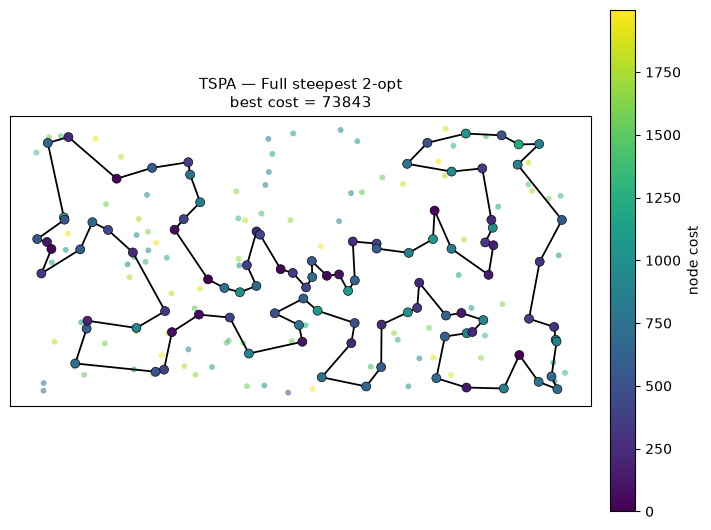

saved figures\lab4_TSPA_baseline_full.png


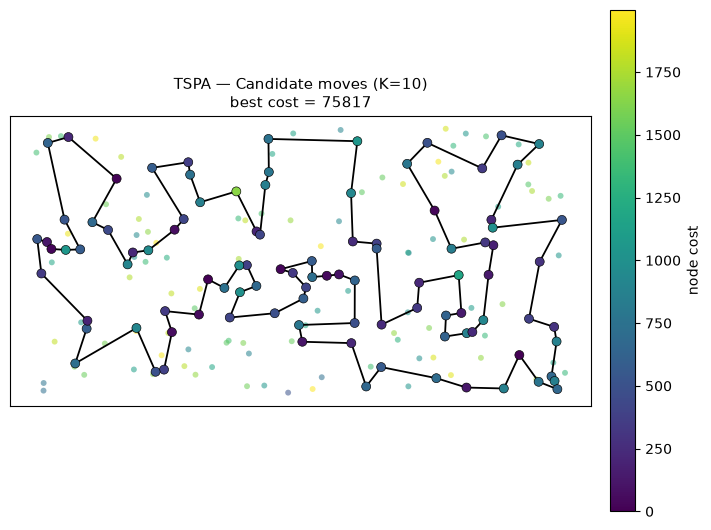

saved figures\lab4_TSPA_candidate_K10.png


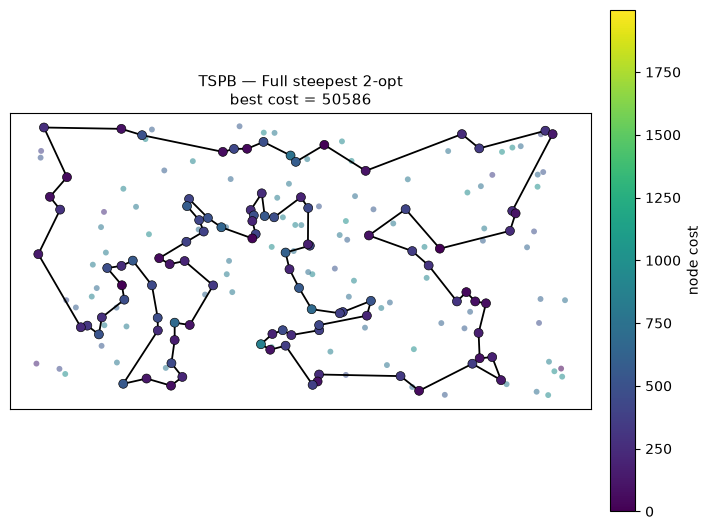

saved figures\lab4_TSPB_baseline_full.png


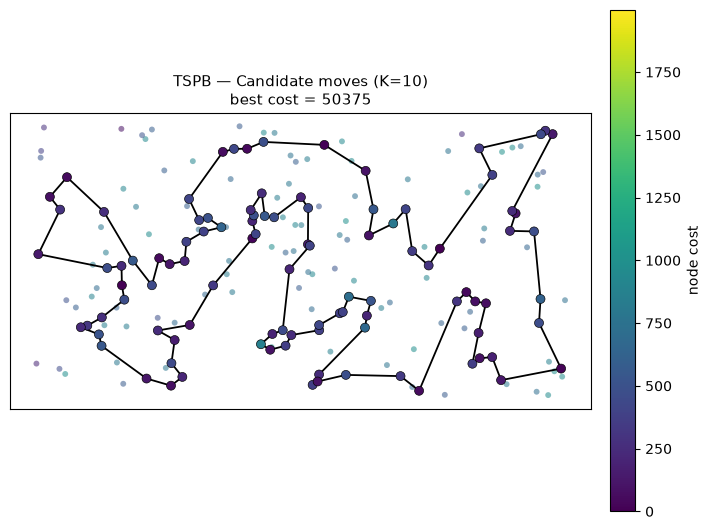

saved figures\lab4_TSPB_candidate_K10.png


In [7]:
all_costs = np.concatenate([problems[n]['costs'] for n in INSTANCES])
norm = Normalize(vmin=int(all_costs.min()), vmax=int(all_costs.max()))
sm = ScalarMappable(norm=norm, cmap='viridis')

PLOT_KEYS = ['baseline_full', f'candidate_K{K_DEFAULT}']
for name in INSTANCES:
    pr = problems[name]
    xy, costs = pr['xy'], pr['costs']
    for key in PLOT_KEYS:
        m = results[name]['methods'][key]
        tour = np.array(m['best_tour'], dtype=int)

        fig, ax = plt.subplots(figsize=(7.2, 5.4))
        ax.scatter(xy[:, 0], xy[:, 1], c=costs, cmap='viridis', norm=norm,
                   s=18, alpha=0.55, linewidths=0, zorder=1)
        path = xy[np.append(tour, tour[0])]
        ax.plot(path[:, 0], path[:, 1], 'k-', lw=1.3, zorder=2)
        ax.scatter(xy[tour, 0], xy[tour, 1], c=costs[tour], cmap='viridis', norm=norm,
                   s=42, edgecolors='black', linewidths=0.45, zorder=3)
        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])
        title = 'Full steepest 2-opt' if key == 'baseline_full' else f'Candidate moves (K={K_DEFAULT})'
        ax.set_title(f'{name} — {title}\nbest cost = {m["best_cost"]}', fontsize=11)
        cb = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.03)
        cb.set_label('node cost')
        fig.tight_layout()

        fname = FIG / f'lab4_{name}_{key}.png'
        fig.savefig(fname, dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print('saved', fname)

## 6. Best solutions as node index lists (0-based)

For each instance: the baseline full steepest solution and the candidate-moves solution with `K = 10`.

In [8]:
for name in INSTANCES:
    print(f'=== {name} (n={results[name]["n"]}, k={results[name]["k"]}) ===')
    for key in ['baseline_full', f'candidate_K{K_DEFAULT}']:
        m = results[name]['methods'][key]
        print(f'{method_label(key)}: cost={m["best_cost"]}')
        print(m['best_tour'])
        print()

=== TSPA (n=200, k=100) ===
Full steepest 2-opt: cost=73843
[82, 31, 48, 80, 91, 157, 71, 4, 76, 132, 180, 28, 102, 185, 35, 51, 16, 67, 144, 53, 179, 52, 177, 36, 99, 131, 33, 9, 54, 8, 142, 164, 85, 93, 50, 3, 169, 1, 178, 184, 186, 136, 163, 29, 17, 55, 101, 147, 47, 130, 159, 146, 170, 153, 78, 88, 107, 64, 57, 182, 151, 42, 89, 113, 106, 150, 174, 176, 72, 134, 158, 192, 181, 58, 84, 41, 140, 45, 73, 135, 98, 87, 141, 187, 2, 171, 69, 127, 97, 161, 30, 123, 152, 108, 49, 168, 63, 149, 116, 60]

Candidate steepest 2-opt, K=10: cost=75817
[170, 153, 193, 78, 88, 107, 64, 57, 182, 158, 192, 58, 135, 73, 84, 131, 36, 177, 179, 52, 67, 144, 53, 140, 45, 87, 102, 185, 35, 156, 28, 180, 141, 30, 187, 2, 171, 161, 69, 127, 97, 168, 116, 149, 63, 11, 49, 60, 31, 48, 80, 108, 152, 160, 123, 90, 132, 76, 91, 157, 71, 4, 18, 51, 16, 139, 112, 115, 154, 62, 33, 9, 54, 134, 176, 174, 81, 106, 150, 151, 42, 89, 113, 93, 50, 3, 85, 164, 186, 136, 178, 29, 55, 101, 1, 169, 147, 47, 130, 159]

=== 

## 7. Solution checking and saved files

Every best tour is checked for length `k`, distinct nodes and valid indices. The best tours are saved
as one-node-per-line CSV files in `solutions/`, ready to paste into the solution checker.

In [9]:
for name in INSTANCES:
    for key in ['baseline_full', f'candidate_K{K_DEFAULT}']:
        m = results[name]['methods'][key]
        tour = [int(v) for v in m['best_tour']]
        ok, msg = check_solution(tour, results[name]['n'], results[name]['k'])
        recomputed = compute_cost(tour, problems[name]['dist'], problems[name]['costs'])
        assert ok, msg
        assert recomputed == m['best_cost']
        path = SOL / f'lab4_{name}_{key}_ids.csv'
        with open(path, 'w') as f:
            for v in tour:
                f.write(f'{v}\n')
        print(f'{name}/{key}: best_ok={ok} best_cost={recomputed} -> {path}')

TSPA/baseline_full: best_ok=True best_cost=73843 -> solutions\lab4_TSPA_baseline_full_ids.csv
TSPA/candidate_K10: best_ok=True best_cost=75817 -> solutions\lab4_TSPA_candidate_K10_ids.csv
TSPB/baseline_full: best_ok=True best_cost=50586 -> solutions\lab4_TSPB_baseline_full_ids.csv
TSPB/candidate_K10: best_ok=True best_cost=50375 -> solutions\lab4_TSPB_candidate_K10_ids.csv


## 8. Conclusions

1. Restricting the steepest local search to candidate moves gives a **large speed-up**: about 3x on
   both instances with `K = 10` (see the time table).
2. The solution quality is only slightly worse for `K = 10`: about 5% on TSPA and essentially the same
   on TSPB. Larger `K` closes the gap but reduces the speed-up.
3. The search evaluates only `O(kK)` candidate pairs per iteration instead of the full
   `O(k(n-k) + k^2)` neighbourhood. No full-neighbourhood scan is performed.
4. Both move types respect the candidate-edge requirement: every applied move introduces the candidate
   edge `(p, v)`, and both possible orientations of the move are evaluated for each candidate edge.

Source code: https://github.com/skalskidaniel/evolutionary-computation/blob/main/lab4.ipynb